# Pharmacy Desert Index (PDI): analysis notebook (2021 data)

Code for *Machine Learning for Healthcare Accessibility: Developing a Pharmacy Desert Index for U.S. Counties* (JMIR Formative Research, manuscript #100048). The saved outputs below are from the run whose results are reported in the paper.

**Input.** `2021_All_county_combined_full_dataset_corrected.csv` (archived with this notebook): 735 counties in 7 states, predictors from the 2021 County Health Rankings release, and the share of each county's population living in pharmacy-desert tracts (`% Living in Desert`, from Nguyen et al., GoodRx, September 2021).

**Outcome.** Following Nguyen et al.'s county definition, a county is a pharmacy desert when more than 50% of its population lives in pharmacy-desert census tracts. The notebook derives `Desert Y/N` directly from `% Living in Desert` (> 0.5), giving 289 deserts and 445 non-deserts among the 734 counties with outcome data. `% Living in Desert` is excluded from the predictors.

**Pipeline.**
1. Convert the four provider ratios to providers per person; drop the one county without outcome data; drop the 10 variables with more than 20% missing values (44 candidate features remain).
2. Split the 734 counties first (stratified 70/10/20: 513 training, 73 validation, 148 test).
3. Impute missing values with training-set state means; standardize with a scaler fit on the training set.
4. Tune five classifiers (Decision Tree, Random Forest, XGBoost, SVM, KNN) and a logistic-regression baseline by grid search on balanced accuracy (5-fold CV on the training set; 3-fold for SVM). Class imbalance is handled with class weights, applied once per model (`fit_weighted`); no oversampling is used. Decision thresholds are tuned by 3-fold inner CV (Youden's J).
5. Select the final model by mean balanced accuracy in 50-fold repeated stratified CV (5-fold × 10 repeats) on the 586 training + validation counties. Within this CV the scaler is fit once on the 586 counties and class weights use their class counts.
6. Evaluate the selected model (trained on the 513 training counties) once on the 148 test counties.
7. Robustness: 100-fold repeated CV (5-fold × 20) and leave-one-state-out CV on all 734 counties (standardized once across them).
8. SHAP (TreeExplainer for the selected XGBoost model) on all 734 counties; feature direction = sign of the Pearson correlation between each feature's standardized values and its SHAP values.
9. PDI = weighted sum of percentile ranks of the 11 features with the largest mean |SHAP|, with weights renormalized to sum to 1 over those 11 features.

**Mapping to the paper.** Cells 7 → Figure 2; 17b → Table 2 and the paired model comparison; 18 → Table 3 and the test-set results for all models; 19–20 → robustness checks (Limitations); 21 → Figure 3 and Table 5; 22 → Tables 4, 6, 7, Figure 4, and the Fisher, Texas worked example; 24 → confusion matrices, Brier scores, and calibration; 24b → paired XGBoost vs logistic regression test.

**Notes on the saved output.**
- With the archived dataset, whose `Desert Y/N` column already follows the > 50% rule, the check in cell 3 prints `Original label reproduces (% Living in Desert > 0): False`, and the crosstab shows the archived label and the derived label agree. (On the original dataset, whose label marked any county with residents in a desert tract, the same check prints `True`.)
- `print_eval` labels every block "(VAL)", including the final test evaluation in cell 18.
- The review-package summary (cell 26) labels the SHAP direction counts "all 46 features"; the analysis uses 44 features.

**Running it.** Open in Google Colab (or Jupyter), run all cells top to bottom, and upload the dataset when prompted. Random seeds are fixed (`RANDOM_STATE = 42`); results can differ slightly with other library versions.

**Revision history.** Round 1: split before any preprocessing (previously SMOTE, scaling, and correlation screening were applied to the whole dataset); class weights instead of SMOTE; model selection by repeated CV; corrected PDI feature directions. Round 2: predictors re-aligned to the 2021 County Health Rankings release; outcome recoded to the > 50% county definition; class-imbalance correction applied exactly once per model; per-fold exports for every model and test-set metrics for every model.

## 0. Setup — install SHAP and upload your data

In [ ]:
# SHAP isn't preinstalled in Colab -- same as your original notebook
!pip install shap


In [ ]:
# Upload the CSV (same as your original notebook)
from google.colab import files
uploaded = files.upload()


Saving 2021_All_county_combined_full_dataset_corrected.csv to 2021_All_county_combined_full_dataset_corrected.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix, classification_report,
    roc_auc_score, average_precision_score, roc_curve
)
from scipy.stats import rankdata

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 1. Load data

Edit `CSV_PATH` below to match the filename you just uploaded.

In [ ]:
CSV_PATH = '2021_All_county_combined_full_dataset_corrected.csv'  # <-- EDIT THIS to match your uploaded 2021 file's exact name
df = pd.read_csv(CSV_PATH)
df.head()


,"County, State",Population,Income (Median),% Children in Poverty,Education (% completed High School),Education (% completed college),Social Association Rate,% Unemployed,Trauma,Suicide rate,...,% Frequent Mental Distress,% Adults with Diabetes,HIV Prevalence Rate,Drug Overdose Mortality Rate,% Uninsured Adults,% Uninsured Children,Other Primary Care Provider Ratio,% Less than 18 Years of Age,% 65 and Over,% Rural
0,"Adams, Pennsylvania",102470,76554,10,90,58,12.2,3.3,78.575448,14.0,...,15,12,142.0,15.0,8,6,1355:1,19.8,21.1,53.7
1,"Allegheny, Pennsylvania",1221744,71973,14,95,80,12.2,4.1,68.900884,15.0,...,14,9,233.0,48.0,6,3,500:1,18.6,19.3,2.5
2,"Armstrong, Pennsylvania",65867,57609,16,92,56,19.5,5.1,60.610770,18.0,...,17,15,53.0,44.0,6,4,1177:1,19.1,22.6,67.5
3,"Beaver, Pennsylvania",165833,67135,18,95,69,14.8,4.5,85.209463,14.0,...,15,12,78.0,41.0,6,3,1171:1,19.2,22.0,25.8
4,"Bedford, Pennsylvania",48337,55517,14,90,52,18.3,4.7,34.477557,21.0,...,17,12,58.0,29.0,9,6,1064:1,19.1,23.4,83.8


## 2. Ratio → per-person conversion

Same transformation as the original notebook — not a leakage issue, so unchanged.

In [ ]:
def extract_numeric_part(s):
    return float(s.split(':')[0]) if isinstance(s, str) else np.nan

def invert_ratio(v):
    return 1 / v if pd.notnull(v) and v != 0 else np.nan

for col, newcol in [
    ('Primary Care Physicians Ratio', 'Primary Care Physicians per Person'),
    ('Dentist Ratio', 'Dentists per Person'),
    ('Mental Health Provider Ratio', 'Mental Health Providers per Person'),
    ('Other Primary Care Provider Ratio', 'Other Primary Care Providers per Person'),
]:
    df[col] = df[col].apply(extract_numeric_part)
    df[newcol] = df[col].apply(invert_ratio)
df = df.drop(columns=['Primary Care Physicians Ratio', 'Dentist Ratio',
                       'Mental Health Provider Ratio', 'Other Primary Care Provider Ratio'])


## 3. Drop the county without outcome data and derive the outcome

The one county with no pharmacy-desert data (San Francisco, California) is dropped rather than imputed. The outcome is derived from `% Living in Desert` with the > 50% county rule. With the archived dataset the label check prints `False` (see the note at the top); the crosstab confirms the archived and derived labels agree.

In [ ]:
n_before = len(df)
df = df[df['% Living in Desert'].notna()].copy()
print(f"[FIX] Dropped {n_before - len(df)} row(s) with missing pharmacy-desert data.")

# ROUND 2 (Reviewer CL major 1): outcome follows Nguyen et al.'s county definition --
# a county is a pharmacy desert if MORE THAN 50% of its population lives in a
# pharmacy-desert census tract. The original 'Desert Y/N' column equals
# (% Living in Desert > 0), i.e. "any population in a desert tract".
pct = pd.to_numeric(df['% Living in Desert'], errors='coerce')
assert pct.notna().all(), "non-numeric '% Living in Desert' values found"
if pct.max() > 1.0:          # defensive: handle a 0-100 percent encoding
    pct = pct / 100.0
orig_label = df['Desert Y/N'].map({'Y': 1, 'N': 0})
print("Original label reproduces (% Living in Desert > 0):",
      bool(((pct > 0).astype(int) == orig_label).all()))
df['Desert Y/N'] = (pct > 0.5).astype(int)
print(pd.crosstab(orig_label, df['Desert Y/N'],
                  rownames=['original (any desert tract)'], colnames=['new (>50% of population)']))
print("New class balance:\n", df['Desert Y/N'].value_counts())
df[['County', 'State']] = df['County, State'].str.split(', ', expand=True)
print("New outcome by state (desert / total):")
print(df.groupby('State')['Desert Y/N'].agg(['sum', 'count']))

[FIX] Dropped 1 row(s) with missing pharmacy-desert data.
Original label reproduces (% Living in Desert > 0): False
new (>50% of population)       0    1
original (any desert tract)          
0                            445    0
1                              0  289
New class balance:
 Desert Y/N
0    445
1    289
Name: count, dtype: int64
New outcome by state (desert / total):
              sum  count
State                   
California     13     57
INDIANA        30     92
KENTUCKY       35    120
MONTANA        43     56
OHIO           24     88
Pennsylvania    9     67
TEXAS         135    254


## 4. Drop columns >20% missing

Computed on the full dataset -- uses only missingness counts, not label information, so this is not the leakage the reviewers flagged.

In [ ]:
missing_frac = df.isnull().mean()
cols_to_drop = [c for c in missing_frac[missing_frac > 0.20].index if c != 'Desert Y/N']
print(f"[Editorial #2, expanded] Columns dropped for >20% missing ({len(cols_to_drop)}): {cols_to_drop}")
df = df.drop(columns=cols_to_drop)


[Editorial #2, expanded] Columns dropped for >20% missing (10): ['Suicide rate', 'Homicide Rate', 'PTSD', 'Psychosis ', '% Disconnected Youth', 'Deppresion ', 'Child Mortality Rate', 'Infant Mortality Rate', 'HIV Prevalence Rate', 'Drug Overdose Mortality Rate']


## 5. Split the counties first

Stratified 70/10/20 split. Every preprocessing step for the final model is fit on the training set only.

In [ ]:
EXCLUDE_ALWAYS = ['Desert Y/N', 'County', 'State', 'County, State', '% Living in Desert']  # Editorial #1
feature_cols = [c for c in df.columns if c not in EXCLUDE_ALWAYS]

X_all = df[feature_cols + ['County', 'State']]
y_all = df['Desert Y/N']

X_train, X_temp, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.3, random_state=RANDOM_STATE, stratify=y_all
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=2/3, random_state=RANDOM_STATE, stratify=y_temp
)
print(f"[FIX] Real-county split: train={len(X_train)}, val={len(X_val)}, test={len(X_test)}")
print("Train class balance:\n", y_train.value_counts())
print("Val class balance:\n", y_val.value_counts())
print("Test class balance:\n", y_test.value_counts())


[FIX] Real-county split: train=513, val=73, test=148
Train class balance:
 Desert Y/N
0    311
1    202
Name: count, dtype: int64
Val class balance:
 Desert Y/N
0    44
1    29
Name: count, dtype: int64
Test class balance:
 Desert Y/N
0    90
1    58
Name: count, dtype: int64


## 6. Impute using training-set state means only

In [ ]:
train_state_means = X_train.groupby('State')[feature_cols].mean()
overall_train_mean = X_train[feature_cols].mean()

def apply_impute(X):
    X = X.copy()
    for state in X['State'].unique():
        mask = X['State'] == state
        fill_vals = train_state_means.loc[state] if state in train_state_means.index else overall_train_mean
        for c in feature_cols:
            fv = fill_vals[c]
            if pd.isna(fv):
                fv = overall_train_mean[c]
            X.loc[mask, c] = X.loc[mask, c].fillna(fv)
    X[feature_cols] = X[feature_cols].fillna(X[feature_cols].mean())
    return X

X_train_imp = apply_impute(X_train)
X_val_imp = apply_impute(X_val)
X_test_imp = apply_impute(X_test)
print("[FIX] Imputation complete (train-fold statistics only).")


[FIX] Imputation complete (train-fold statistics only).


## 7. Correlation analysis (Figure 2)

Computed on the training set only, after imputation. Used descriptively; correlations are not used to select features. All 44 candidate features go to every model.

Train-only correlation with target (sorted):
% With Access to Exercise Opportunities       -0.377448
% Vaccinated                                  -0.367766
Traffic Volume                                -0.358496
% Households with Broadband Access            -0.310091
% Severe Housing Problems                     -0.279042
% Households with Severe Cost Burden          -0.263785
% with Annual Mammogram                       -0.253217
Population                                    -0.243518
Mental Health Providers per Person            -0.236088
Education (% completed college)               -0.202255
Food Environment Index                        -0.196891
Income (Median)                               -0.189127
% Adults with Obesity                         -0.162468
% Insufficient Sleep                          -0.137925
% Low Birthweight                             -0.113510
% Unemployed                                  -0.109781
Other Primary Care Providers per Person       -0.106973
% L

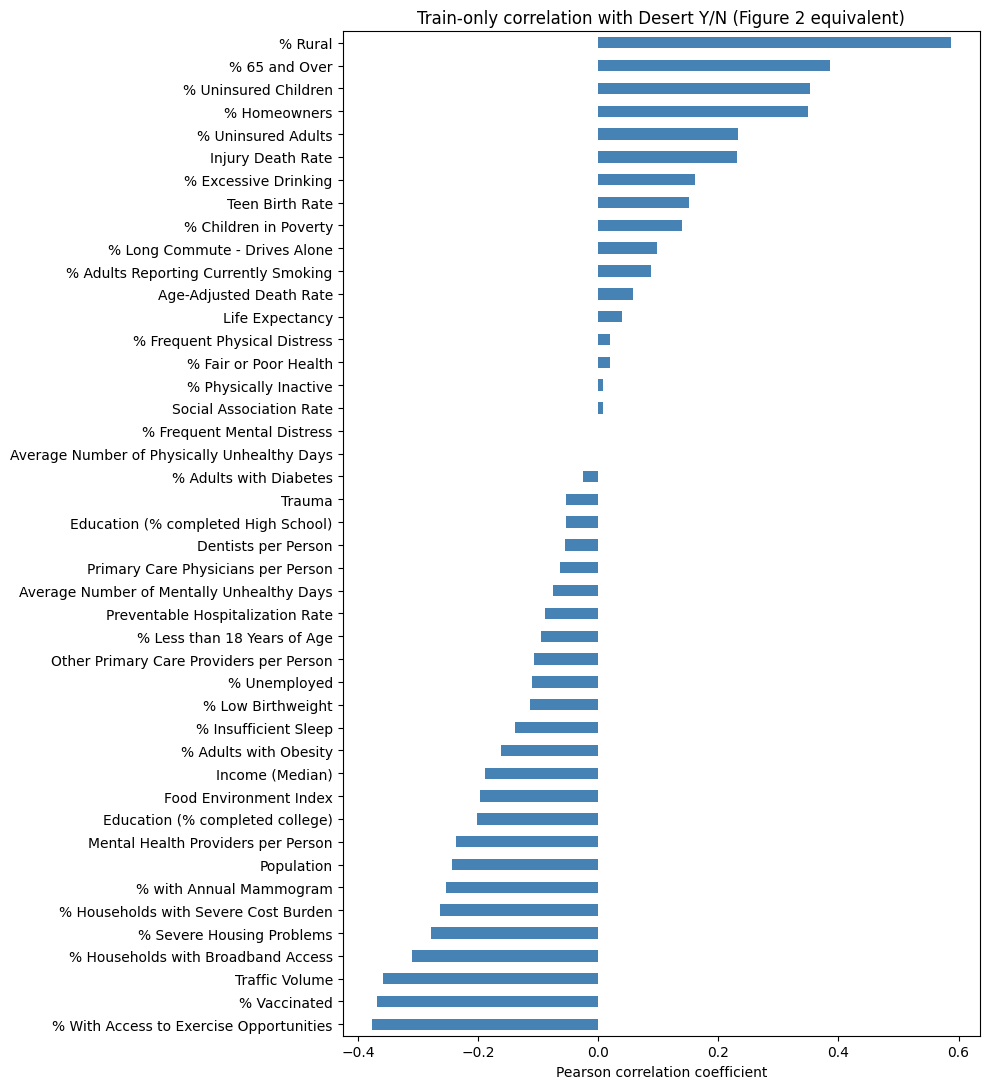

In [ ]:
train_corr_df = X_train_imp[feature_cols].copy()
train_corr_df['Desert Y/N'] = y_train.values
corr_with_target = train_corr_df.corr()['Desert Y/N'].drop('Desert Y/N').sort_values()
print("Train-only correlation with target (sorted):")
print(corr_with_target)

plt.figure(figsize=(10, max(6, len(feature_cols) * 0.25)))
corr_with_target.sort_values().plot(kind='barh', color='steelblue')
plt.title('Train-only correlation with Desert Y/N (Figure 2 equivalent)')
plt.xlabel('Pearson correlation coefficient')
plt.tight_layout()
plt.show()


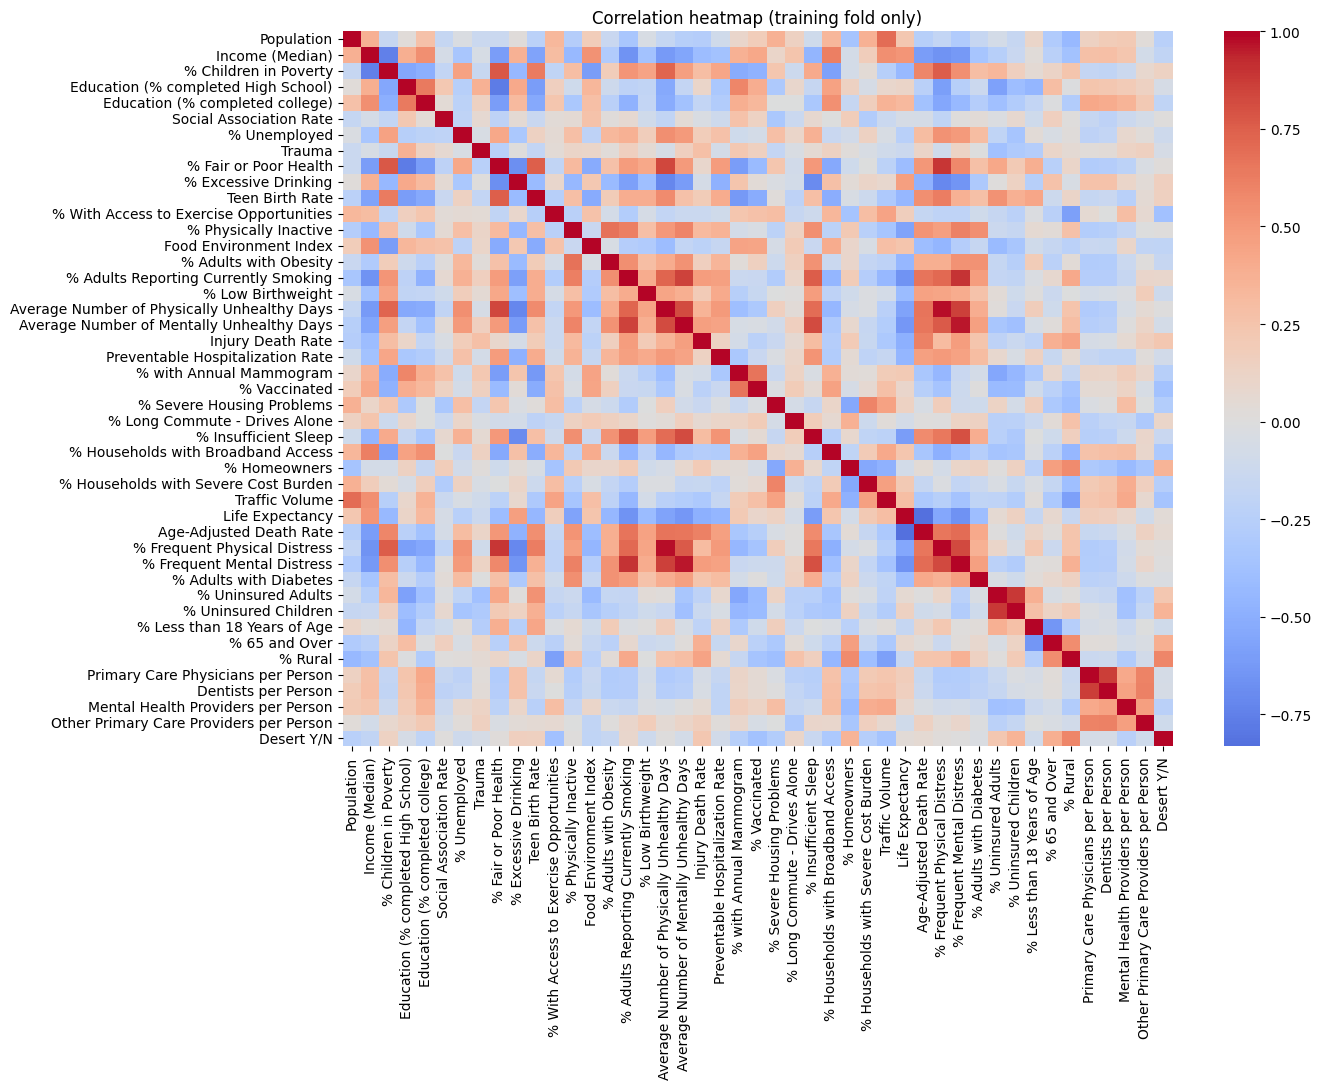

In [ ]:
plt.figure(figsize=(14, 11))
sns.heatmap(train_corr_df.corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Correlation heatmap (training fold only)')
plt.tight_layout()
plt.show()


## 9. Scale (fit on the training set only)

`sample_weight_train` gives each class equal total weight; it is used only by models without a `class_weight` option (XGBoost).

In [ ]:
scaler = StandardScaler().fit(X_train_imp[feature_cols])
X_train_scaled = scaler.transform(X_train_imp[feature_cols])
X_val_scaled = scaler.transform(X_val_imp[feature_cols])
X_test_scaled = scaler.transform(X_test_imp[feature_cols])

y_train_arr = y_train.values
n_pos = (y_train_arr == 1).sum()
n_neg = (y_train_arr == 0).sum()
sample_weight_train = np.where(y_train_arr == 0, n_pos / n_neg, 1.0)  # each class gets equal total weight (used only by XGBoost)


## 10. Shared model-fitting framework

Every model below (baselines and all five classifiers) goes through the same four steps, so the comparison in Table 2 is fair and consistent:
1. Manual grid search, scored by **balanced accuracy** via 5-fold CV on the training fold only (3-fold for SVM, to keep runtime reasonable).
2. Refit the best hyperparameters on the full training fold.
3. Tune the decision threshold via inner 3-fold CV (Youden's J) on the training fold only — no validation/test leakage.
4. Evaluate on validation at the tuned threshold: confusion matrix, balanced accuracy, sensitivity, specificity, PPV, NPV, ROC-AUC, PR-AUC.

In [ ]:
def fit_weighted(m, X, y, sw):
    """Apply the class-imbalance correction exactly once.
    Models built with class_weight='balanced' (Decision Tree, Random Forest, SVM,
    Logistic Regression) are fit WITHOUT sample weights; models without a class_weight
    option (XGBoost) get the balancing sample weights; KNN cannot take weights."""
    if getattr(m, 'class_weight', None) is not None:
        return m.fit(X, y)
    try:
        return m.fit(X, y, sample_weight=sw)
    except TypeError:
        return m.fit(X, y)

def youden_threshold(y_true, y_prob):
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    return thr[np.argmax(tpr - fpr)]

def tune_threshold_inner_cv(build_fn, X, y, sw, n_splits=3):
    y = np.asarray(y)
    inner = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    oof = np.zeros(len(y))
    for tr, te in inner.split(X, y):
        m = build_fn()
        fit_weighted(m, X[tr], y[tr], sw[tr])
        oof[te] = m.predict_proba(X[te])[:, 1]
    return youden_threshold(y, oof)

def eval_at(y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    cm = confusion_matrix(y_true, pred)
    tn, fp, fn, tp = cm.ravel()
    out = dict(
        threshold=thr,
        balanced_accuracy=balanced_accuracy_score(y_true, pred),
        accuracy=accuracy_score(y_true, pred),
        sensitivity=tp / (tp + fn) if (tp + fn) else np.nan,
        specificity=tn / (tn + fp) if (tn + fp) else np.nan,
        ppv=tp / (tp + fp) if (tp + fp) else np.nan,
        npv=tn / (tn + fn) if (tn + fn) else np.nan,
    )
    try:
        out['roc_auc'] = roc_auc_score(y_true, prob)
        out['pr_auc'] = average_precision_score(y_true, prob)
    except Exception:
        out['roc_auc'] = np.nan
        out['pr_auc'] = np.nan
    return out, cm

def print_eval(name, metrics, cm):
    print(f"\n=== {name} (VAL) ===")
    print("Confusion matrix [[TN,FP],[FN,TP]]:\n", cm)
    for k, v in metrics.items():
        print(f"  {k}: {v:.3f}" if isinstance(v, (int, float)) and not pd.isna(v) else f"  {k}: {v}")

def manual_grid_search_cv(build_fn, param_grid, X, y, sw, cv=5):
    best_score = -np.inf
    best_params = None
    skf = StratifiedKFold(n_splits=cv, shuffle=True, random_state=RANDOM_STATE)
    for params in ParameterGrid(param_grid):
        scores = []
        for tr, te in skf.split(X, y):
            m = build_fn(**params)
            fit_weighted(m, X[tr], y[tr], sw[tr])
            pred = m.predict(X[te])
            scores.append(balanced_accuracy_score(y[te], pred))
        mean_score = np.mean(scores)
        if mean_score > best_score:
            best_score = mean_score
            best_params = params
    return best_params, best_score

def plot_feature_importance(name, importances, feature_names, top_n=20):
    s = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(top_n)
    plt.figure(figsize=(12, 6))
    s.plot(kind='bar', color='skyblue')
    plt.title(f'Feature Importances -- {name}')
    plt.ylabel('Importance')
    plt.tight_layout()
    plt.show()

# results and fitted models get collected here for the comparison table + best-model selection
results = {}
fitted_models = {}
build_fns = {}


## 11. Baselines — trivial majority-class + logistic regression

*(Editorial #10; Reviewer CL #5/#6)*

In [ ]:
majority_class = int(pd.Series(y_train_arr).mode()[0])
trivial_pred_val = np.full(len(y_val), majority_class)
cm = confusion_matrix(y_val, trivial_pred_val)
tn, fp, fn, tp = cm.ravel()
results['Trivial (majority class)'] = dict(
    threshold=np.nan, balanced_accuracy=balanced_accuracy_score(y_val, trivial_pred_val),
    accuracy=accuracy_score(y_val, trivial_pred_val),
    sensitivity=tp / (tp + fn) if (tp + fn) else np.nan, specificity=tn / (tn + fp) if (tn + fp) else np.nan,
    ppv=tp / (tp + fp) if (tp + fp) else np.nan, npv=tn / (tn + fn) if (tn + fn) else np.nan,
    roc_auc=0.5, pr_auc=np.nan,
)
print_eval('Trivial majority-class baseline', results['Trivial (majority class)'], cm)



=== Trivial majority-class baseline (VAL) ===
Confusion matrix [[TN,FP],[FN,TP]]:
 [[44  0]
 [29  0]]
  threshold: nan
  balanced_accuracy: 0.500
  accuracy: 0.603
  sensitivity: 0.000
  specificity: 1.000
  ppv: nan
  npv: 0.603
  roc_auc: 0.500
  pr_auc: nan


Best Logistic Regression params: {'C': 1} | CV balanced accuracy: 0.81

=== Logistic Regression baseline (VAL) ===
Confusion matrix [[TN,FP],[FN,TP]]:
 [[39  5]
 [ 6 23]]
  threshold: 0.610
  balanced_accuracy: 0.840
  accuracy: 0.849
  sensitivity: 0.793
  specificity: 0.886
  ppv: 0.821
  npv: 0.867
  roc_auc: 0.937
  pr_auc: 0.914


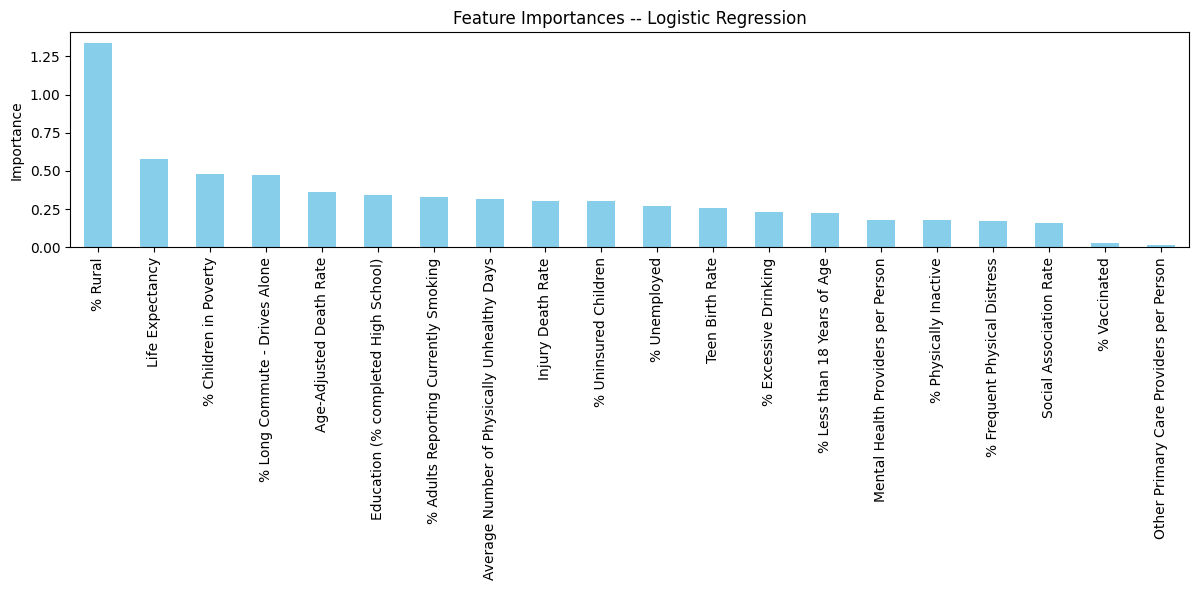

In [ ]:
lr_grid = {'C': [0.05, 0.1, 0.5, 1, 5]}
def build_lr(**p):
    return LogisticRegression(max_iter=3000, class_weight='balanced', random_state=RANDOM_STATE, **p)

lr_best_params, lr_cv_score = manual_grid_search_cv(build_lr, lr_grid, X_train_scaled, y_train_arr, sample_weight_train, cv=5)
print('Best Logistic Regression params:', lr_best_params, '| CV balanced accuracy:', round(lr_cv_score, 3))
build_fns['Logistic Regression'] = lambda: build_lr(**lr_best_params)
lr = build_fns['Logistic Regression']()
lr.fit(X_train_scaled, y_train_arr)
fitted_models['Logistic Regression'] = lr
thr = tune_threshold_inner_cv(build_fns['Logistic Regression'], X_train_scaled, y_train_arr, sample_weight_train)
prob_val = lr.predict_proba(X_val_scaled)[:, 1]
results['Logistic Regression'], cm = eval_at(y_val, prob_val, thr)
print_eval('Logistic Regression baseline', results['Logistic Regression'], cm)

plot_feature_importance('Logistic Regression', lr.coef_[0], feature_cols)


## 12. Decision Tree

Best Decision Tree params: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2} | CV balanced accuracy: 0.8

=== Decision Tree (VAL) ===
Confusion matrix [[TN,FP],[FN,TP]]:
 [[35  9]
 [ 4 25]]
  threshold: 0.644
  balanced_accuracy: 0.829
  accuracy: 0.822
  sensitivity: 0.862
  specificity: 0.795
  ppv: 0.735
  npv: 0.897
  roc_auc: 0.896
  pr_auc: 0.791


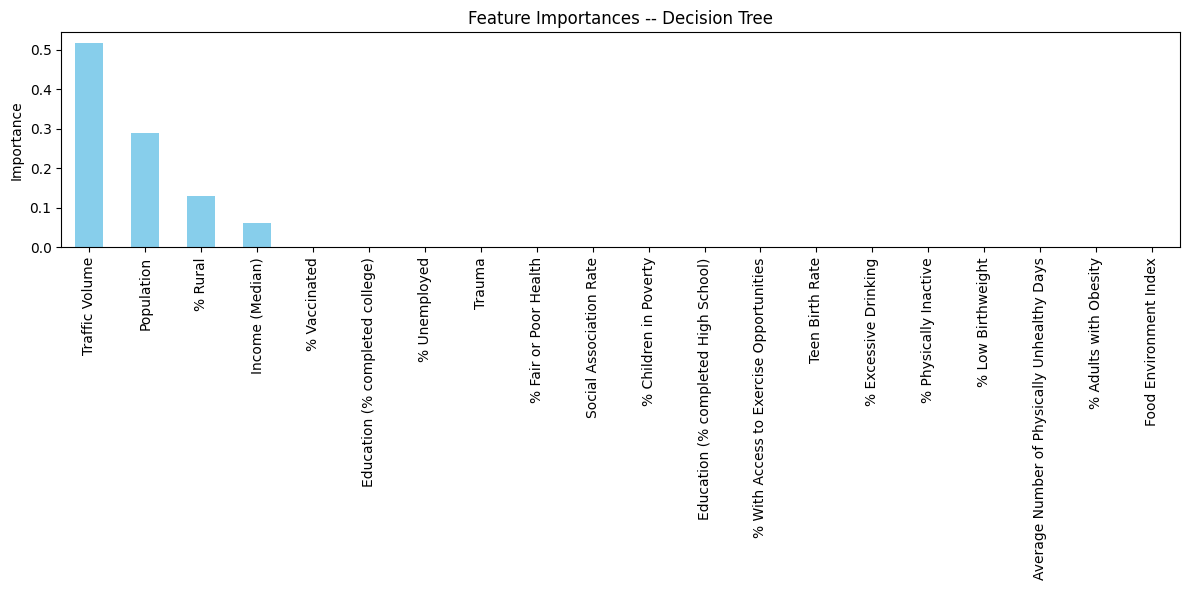

In [ ]:
dt_grid = {'max_depth': [3, 5, 7, 10], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4], 'criterion': ['gini', 'entropy']}
def build_dt(**p):
    return DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight='balanced', **p)

dt_best_params, dt_cv_score = manual_grid_search_cv(build_dt, dt_grid, X_train_scaled, y_train_arr, sample_weight_train, cv=5)
print('Best Decision Tree params:', dt_best_params, '| CV balanced accuracy:', round(dt_cv_score, 3))
build_fns['Decision Tree'] = lambda: build_dt(**dt_best_params)
dt = build_fns['Decision Tree']()
dt.fit(X_train_scaled, y_train_arr)
fitted_models['Decision Tree'] = dt
thr = tune_threshold_inner_cv(build_fns['Decision Tree'], X_train_scaled, y_train_arr, sample_weight_train)
prob_val = dt.predict_proba(X_val_scaled)[:, 1]
results['Decision Tree'], cm = eval_at(y_val, prob_val, thr)
print_eval('Decision Tree', results['Decision Tree'], cm)

plot_feature_importance('Decision Tree', dt.feature_importances_, feature_cols)


## 13. Random Forest

Best Random Forest params: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200} | CV balanced accuracy: 0.83

=== Random Forest (VAL) ===
Confusion matrix [[TN,FP],[FN,TP]]:
 [[39  5]
 [ 4 25]]
  threshold: 0.484
  balanced_accuracy: 0.874
  accuracy: 0.877
  sensitivity: 0.862
  specificity: 0.886
  ppv: 0.833
  npv: 0.907
  roc_auc: 0.947
  pr_auc: 0.922


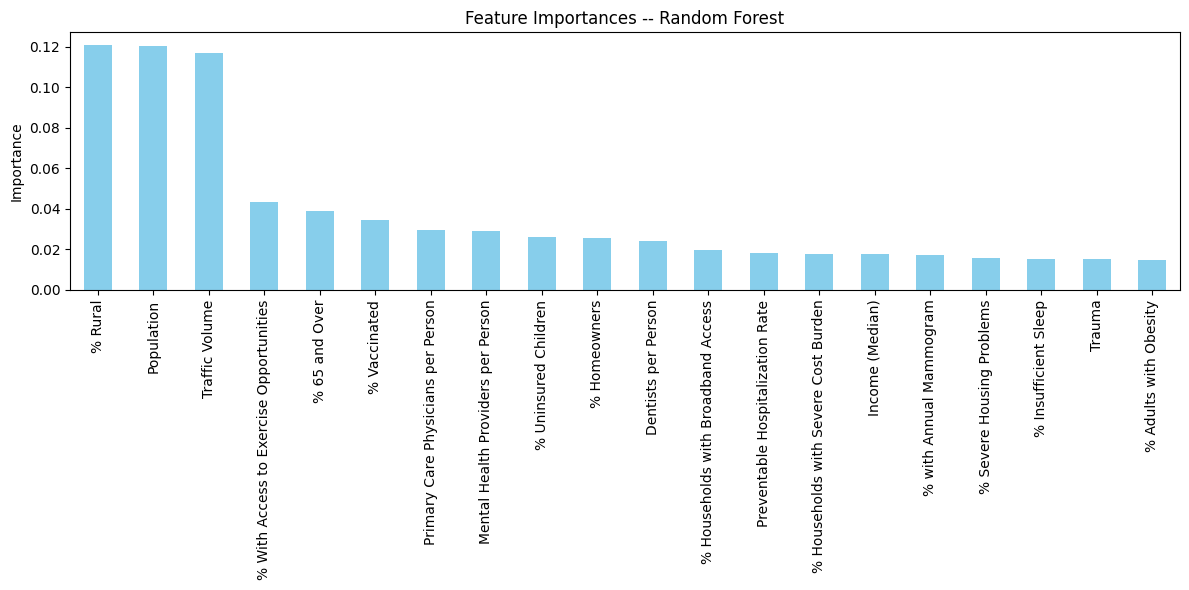

In [ ]:
rf_grid = {'n_estimators': [100, 200, 300], 'max_depth': [None, 10, 15, 20], 'min_samples_split': [2, 5], 'min_samples_leaf': [1, 2]}
def build_rf(**p):
    return RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced', **p)

rf_best_params, rf_cv_score = manual_grid_search_cv(build_rf, rf_grid, X_train_scaled, y_train_arr, sample_weight_train, cv=5)
print('Best Random Forest params:', rf_best_params, '| CV balanced accuracy:', round(rf_cv_score, 3))
build_fns['Random Forest'] = lambda: build_rf(**rf_best_params)
rf = build_fns['Random Forest']()
rf.fit(X_train_scaled, y_train_arr)
fitted_models['Random Forest'] = rf
thr = tune_threshold_inner_cv(build_fns['Random Forest'], X_train_scaled, y_train_arr, sample_weight_train)
prob_val = rf.predict_proba(X_val_scaled)[:, 1]
results['Random Forest'], cm = eval_at(y_val, prob_val, thr)
print_eval('Random Forest', results['Random Forest'], cm)

plot_feature_importance('Random Forest', rf.feature_importances_, feature_cols)


## 14. XGBoost

The grid favors shallow, regularized configurations (`max_depth` 2–5, modest learning rates, L2 regularization), which suit a dataset of this size.

Best XGBoost params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'reg_lambda': 1.0} | CV balanced accuracy: 0.855

=== XGBoost (VAL) ===
Confusion matrix [[TN,FP],[FN,TP]]:
 [[40  4]
 [ 3 26]]
  threshold: 0.463
  balanced_accuracy: 0.903
  accuracy: 0.904
  sensitivity: 0.897
  specificity: 0.909
  ppv: 0.867
  npv: 0.930
  roc_auc: 0.949
  pr_auc: 0.915


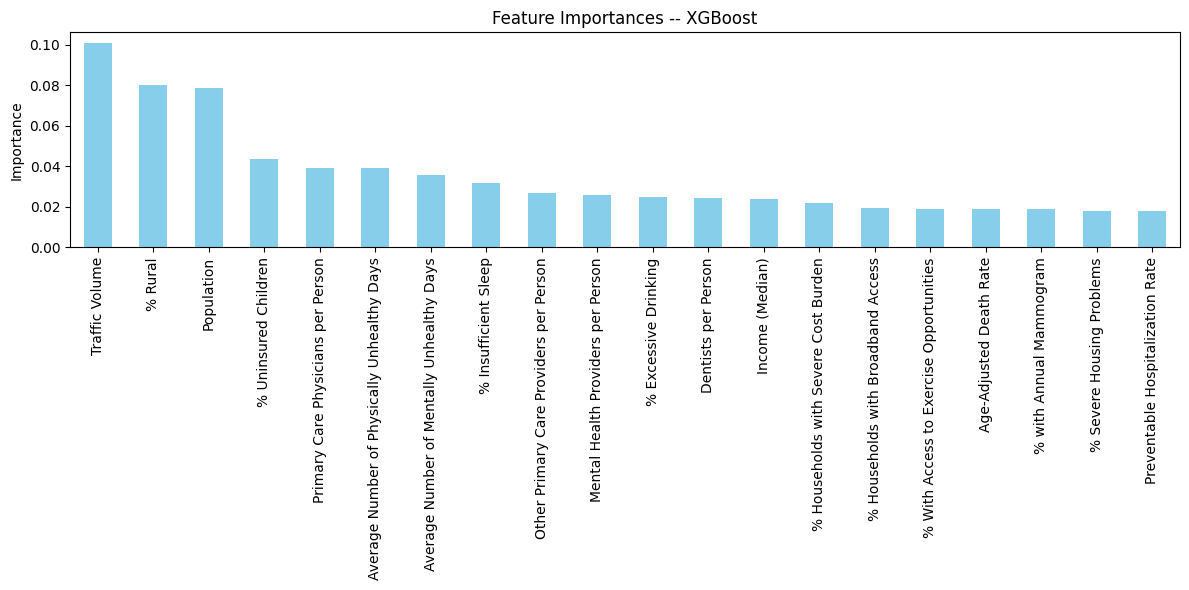

In [ ]:
from xgboost import XGBClassifier

xgb_grid = {'max_depth': [2, 3, 4, 5], 'n_estimators': [100, 150, 200], 'learning_rate': [0.05, 0.1], 'reg_lambda': [1.0, 2.0, 3.0]}
def build_xgb(**p):
    return XGBClassifier(subsample=0.8, colsample_bytree=0.8, eval_metric='logloss', random_state=RANDOM_STATE, **p)

xgb_best_params, xgb_cv_score = manual_grid_search_cv(build_xgb, xgb_grid, X_train_scaled, y_train_arr, sample_weight_train, cv=5)
print('Best XGBoost params:', xgb_best_params, '| CV balanced accuracy:', round(xgb_cv_score, 3))
build_fns['XGBoost'] = lambda: build_xgb(**xgb_best_params)
xgb_model = build_fns['XGBoost']()
xgb_model.fit(X_train_scaled, y_train_arr, sample_weight=sample_weight_train)
fitted_models['XGBoost'] = xgb_model
thr = tune_threshold_inner_cv(build_fns['XGBoost'], X_train_scaled, y_train_arr, sample_weight_train)
prob_val = xgb_model.predict_proba(X_val_scaled)[:, 1]
results['XGBoost'], cm = eval_at(y_val, prob_val, thr)
print_eval('XGBoost', results['XGBoost'], cm)

plot_feature_importance('XGBoost', xgb_model.feature_importances_, feature_cols)


## 15. Support Vector Machine

`probability=True` is required so we can tune a threshold and compute ROC-AUC/PR-AUC consistently with the other models (the original notebook didn't need this since it only used `.predict()`).

In [ ]:
svm_grid = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf', 'poly'], 'gamma': ['scale', 'auto']}
def build_svm(**p):
    return SVC(probability=True, random_state=RANDOM_STATE, class_weight='balanced', **p)

svm_best_params, svm_cv_score = manual_grid_search_cv(build_svm, svm_grid, X_train_scaled, y_train_arr, sample_weight_train, cv=3)
print('Best SVM params:', svm_best_params, '| CV balanced accuracy:', round(svm_cv_score, 3))
build_fns['SVM'] = lambda: build_svm(**svm_best_params)
svm_model = build_fns['SVM']()
svm_model.fit(X_train_scaled, y_train_arr)
fitted_models['SVM'] = svm_model
thr = tune_threshold_inner_cv(build_fns['SVM'], X_train_scaled, y_train_arr, sample_weight_train, n_splits=3)
prob_val = svm_model.predict_proba(X_val_scaled)[:, 1]
results['SVM'], cm = eval_at(y_val, prob_val, thr)
print_eval('SVM', results['SVM'], cm)

if svm_model.kernel == 'linear':
    plot_feature_importance('SVM (linear)', svm_model.coef_[0], feature_cols)
else:
    print(f"Best SVM kernel is '{svm_model.kernel}' (non-linear) -- coefficient-based feature importance doesn't apply.")


Best SVM params: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'} | CV balanced accuracy: 0.829

=== SVM (VAL) ===
Confusion matrix [[TN,FP],[FN,TP]]:
 [[35  9]
 [ 5 24]]
  threshold: 0.424
  balanced_accuracy: 0.812
  accuracy: 0.808
  sensitivity: 0.828
  specificity: 0.795
  ppv: 0.727
  npv: 0.875
  roc_auc: 0.928
  pr_auc: 0.908
Best SVM kernel is 'rbf' (non-linear) -- coefficient-based feature importance doesn't apply.


## 16. K-Nearest Neighbors

KNN has no native feature-importance measure (same as the original notebook -- no feature importance section was produced for KNN there either).

In [ ]:
knn_grid = {'n_neighbors': [3, 5, 7, 9, 11], 'weights': ['uniform', 'distance'], 'metric': ['euclidean', 'manhattan', 'minkowski']}
def build_knn(**p):
    return KNeighborsClassifier(**p)

knn_best_params, knn_cv_score = manual_grid_search_cv(build_knn, knn_grid, X_train_scaled, y_train_arr, sample_weight_train, cv=5)
print('Best KNN params:', knn_best_params, '| CV balanced accuracy:', round(knn_cv_score, 3))
build_fns['KNN'] = lambda: build_knn(**knn_best_params)
knn_model = build_fns['KNN']()
knn_model.fit(X_train_scaled, y_train_arr)
fitted_models['KNN'] = knn_model
thr = tune_threshold_inner_cv(build_fns['KNN'], X_train_scaled, y_train_arr, sample_weight_train)
prob_val = knn_model.predict_proba(X_val_scaled)[:, 1]
results['KNN'], cm = eval_at(y_val, prob_val, thr)
print_eval('KNN', results['KNN'], cm)


Best KNN params: {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'uniform'} | CV balanced accuracy: 0.785

=== KNN (VAL) ===
Confusion matrix [[TN,FP],[FN,TP]]:
 [[36  8]
 [ 3 26]]
  threshold: 0.400
  balanced_accuracy: 0.857
  accuracy: 0.849
  sensitivity: 0.897
  specificity: 0.818
  ppv: 0.765
  npv: 0.923
  roc_auc: 0.936
  pr_auc: 0.891


## 17. Model comparison — Table 2 equivalent

Built programmatically from the `results` dict above (the original notebook hard-coded these numbers by hand from earlier cell outputs — this version reads them directly from the fitted models, so the table can't drift out of sync with the actual run).

In [ ]:
comparison_df = pd.DataFrame(results).T
comparison_df = comparison_df[['threshold', 'balanced_accuracy', 'accuracy', 'sensitivity', 'specificity', 'ppv', 'npv', 'roc_auc', 'pr_auc']]
comparison_df = comparison_df.sort_values('balanced_accuracy', ascending=False)
print("=== Model comparison on VALIDATION (real, imbalanced counties) -- Table 2 equivalent ===")
comparison_df.round(3)


=== Model comparison on VALIDATION (real, imbalanced counties) -- Table 2 equivalent ===


,threshold,balanced_accuracy,accuracy,sensitivity,specificity,ppv,npv,roc_auc,pr_auc
XGBoost,0.463,0.903,0.904,0.897,0.909,0.867,0.930,0.949,0.915
Random Forest,0.484,0.874,0.877,0.862,0.886,0.833,0.907,0.947,0.922
KNN,0.400,0.857,0.849,0.897,0.818,0.765,0.923,0.936,0.891
Logistic Regression,0.610,0.840,0.849,0.793,0.886,0.821,0.867,0.937,0.914
Decision Tree,0.644,0.829,0.822,0.862,0.795,0.735,0.897,0.896,0.791
SVM,0.424,0.812,0.808,0.828,0.795,0.727,0.875,0.928,0.908
Trivial (majority class),NaN,0.500,0.603,0.000,1.000,NaN,0.603,0.500,NaN


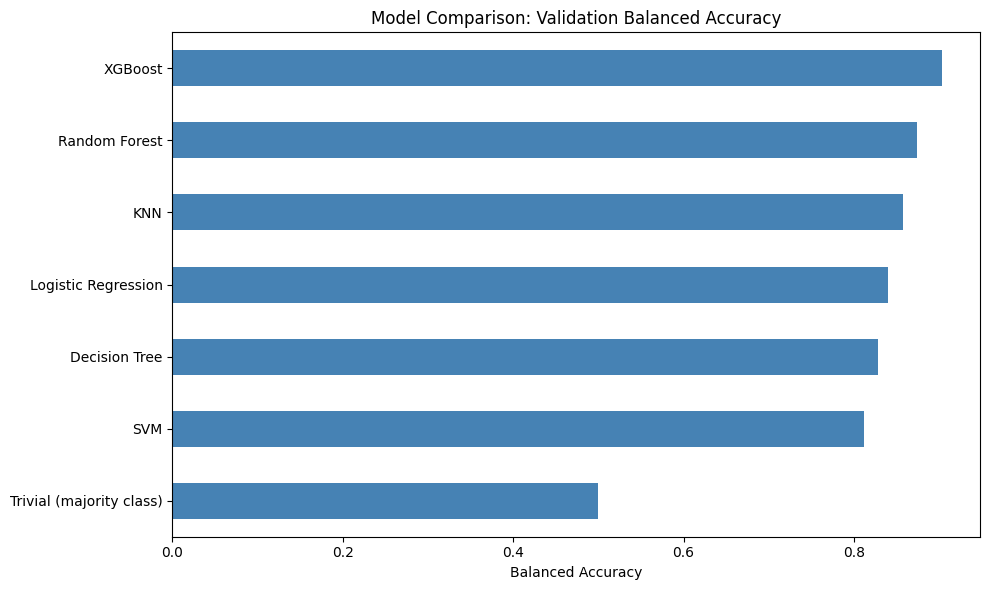

<Figure size 1000x600 with 0 Axes>

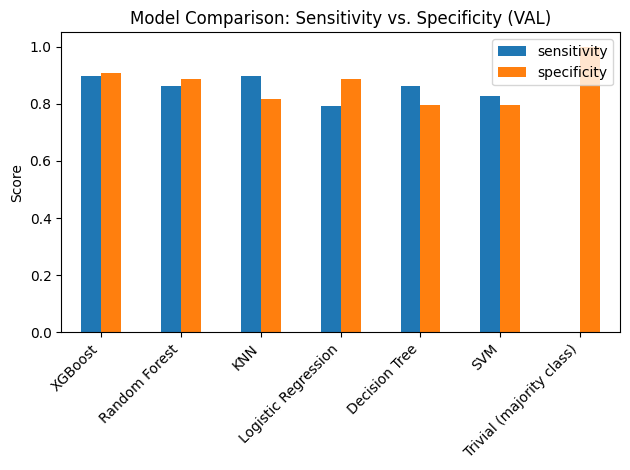

In [ ]:
plt.figure(figsize=(10, 6))
comparison_df['balanced_accuracy'].sort_values().plot(kind='barh', color='steelblue')
plt.title('Model Comparison: Validation Balanced Accuracy')
plt.xlabel('Balanced Accuracy')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
comparison_df[['sensitivity', 'specificity']].plot(kind='bar')
plt.title('Model Comparison: Sensitivity vs. Specificity (VAL)')
plt.ylabel('Score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 17b. Model selection by repeated cross-validation (Table 2)

The validation table above comes from a single 73-county split, which is too small to choose between models reliably. This cell re-scores the five tuned classifiers (hyperparameters from the grid searches above) with repeated stratified 5-fold cross-validation on the 586 training + validation counties (50 folds: 5-fold × 10 repeats). **The final model is selected from this table.** Within this cross-validation the scaler is fit once on the 586 counties and class weights use their class counts. The next cell exports per-fold AUC and balanced accuracy for every model, including logistic regression, on the identical folds, for the paired comparison reported in the paper.

In [ ]:
X_trainval_imp = apply_impute(pd.concat([X_train, X_val]))
y_trainval = pd.concat([y_train, y_val])
scaler_cv = StandardScaler().fit(X_trainval_imp[feature_cols])
X_trainval_scaled = scaler_cv.transform(X_trainval_imp[feature_cols])
y_trainval_arr = y_trainval.values
sw_trainval = np.where(y_trainval_arr == 0, (y_trainval_arr == 1).sum() / max((y_trainval_arr == 0).sum(), 1), 1.0)

cv_candidates = ['Decision Tree', 'Random Forest', 'XGBoost', 'SVM', 'KNN']
rskf_sel = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
cv_robust_results = {}
for name in cv_candidates:
    build_fn = build_fns[name]
    fold_aucs, fold_bas = [], []
    for tr_idx, te_idx in rskf_sel.split(X_trainval_scaled, y_trainval_arr):
        m = build_fn()
        fit_weighted(m, X_trainval_scaled[tr_idx], y_trainval_arr[tr_idx], sw_trainval[tr_idx])
        prob = m.predict_proba(X_trainval_scaled[te_idx])[:, 1]
        fold_aucs.append(roc_auc_score(y_trainval_arr[te_idx], prob))
        fold_bas.append(balanced_accuracy_score(y_trainval_arr[te_idx], (prob >= 0.5).astype(int)))
    cv_robust_results[name] = dict(
        auc_mean=np.mean(fold_aucs), auc_sd=np.std(fold_aucs),
        balanced_accuracy_mean=np.mean(fold_bas), balanced_accuracy_sd=np.std(fold_bas),
    )
    print(f"[CV-robust, {name}] AUC={np.mean(fold_aucs):.3f}+/-{np.std(fold_aucs):.3f}  "
          f"Balanced accuracy@0.5={np.mean(fold_bas):.3f}+/-{np.std(fold_bas):.3f}")

cv_robust_df = pd.DataFrame(cv_robust_results).T.sort_values('balanced_accuracy_mean', ascending=False)
print("\n=== Robust (50-fold repeated CV) model comparison -- this table drives model selection ===")
cv_robust_df.round(3)


[CV-robust, Decision Tree] AUC=0.861+/-0.029  Balanced accuracy@0.5=0.793+/-0.038
[CV-robust, Random Forest] AUC=0.923+/-0.021  Balanced accuracy@0.5=0.833+/-0.033
[CV-robust, XGBoost] AUC=0.923+/-0.021  Balanced accuracy@0.5=0.842+/-0.030
[CV-robust, SVM] AUC=0.906+/-0.021  Balanced accuracy@0.5=0.816+/-0.032
[CV-robust, KNN] AUC=0.872+/-0.021  Balanced accuracy@0.5=0.770+/-0.026

=== Robust (50-fold repeated CV) model comparison -- this table drives model selection ===


,auc_mean,auc_sd,balanced_accuracy_mean,balanced_accuracy_sd
XGBoost,0.923,0.021,0.842,0.030
Random Forest,0.923,0.021,0.833,0.033
SVM,0.906,0.021,0.816,0.032
Decision Tree,0.861,0.029,0.793,0.038
KNN,0.872,0.021,0.770,0.026


In [ ]:
# ROUND 2 (Reviewer CL major 5): per-fold AUC and balanced accuracy for EVERY model,
# including logistic regression, on the identical 50 repeated-CV folds used for model
# selection above, so any two models can be compared fold-by-fold with uncertainty.
fold_rows = []
rskf_all = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
for name in cv_candidates + ['Logistic Regression']:
    build_fn = build_fns[name]
    for k, (tr_idx, te_idx) in enumerate(rskf_all.split(X_trainval_scaled, y_trainval_arr)):
        m = build_fn()
        fit_weighted(m, X_trainval_scaled[tr_idx], y_trainval_arr[tr_idx], sw_trainval[tr_idx])
        prob = m.predict_proba(X_trainval_scaled[te_idx])[:, 1]
        fold_rows.append({'model': name, 'repeat': k // 5, 'fold': k % 5,
                          'auc': roc_auc_score(y_trainval_arr[te_idx], prob),
                          'balanced_accuracy': balanced_accuracy_score(y_trainval_arr[te_idx], (prob >= 0.5).astype(int))})
all_models_fold_metrics_df = pd.DataFrame(fold_rows)
all_models_fold_metrics_df.to_csv('all_models_fold_metrics.csv', index=False)
print(all_models_fold_metrics_df.groupby('model')[['auc', 'balanced_accuracy']].agg(['mean', 'std']).round(4))

                        auc         balanced_accuracy        
                       mean     std              mean     std
model                                                        
Decision Tree        0.8606  0.0290            0.7926  0.0385
KNN                  0.8717  0.0215            0.7704  0.0267
Logistic Regression  0.9017  0.0256            0.8063  0.0376
Random Forest        0.9228  0.0215            0.8325  0.0334
SVM                  0.9062  0.0207            0.8164  0.0320
XGBoost              0.9226  0.0217            0.8420  0.0301


## 18. Select the final model and evaluate it once on the test set (Table 3)

The model with the highest mean 50-fold balanced accuracy is selected (logistic regression and the trivial baseline are comparators, not candidates). It is the model fit on the 513 training counties and is evaluated once on the 148 test counties at its training-set-tuned threshold. The second cell scores every fitted model on the test set at its own threshold, for comparison only.

In [ ]:
best_model_name = cv_robust_df['balanced_accuracy_mean'].idxmax()
print(f"Best model by 50-fold repeated CV (balanced accuracy): {best_model_name}")

best_model = fitted_models[best_model_name]
best_build_fn = build_fns[best_model_name]
best_threshold = results[best_model_name]['threshold']

test_prob = best_model.predict_proba(X_test_scaled)[:, 1]
test_metrics, test_cm = eval_at(y_test, test_prob, best_threshold)
print_eval(f'{best_model_name} -- FINAL TEST EVALUATION', test_metrics, test_cm)


Best model by 50-fold repeated CV (balanced accuracy): XGBoost

=== XGBoost -- FINAL TEST EVALUATION (VAL) ===
Confusion matrix [[TN,FP],[FN,TP]]:
 [[79 11]
 [ 5 53]]
  threshold: 0.463
  balanced_accuracy: 0.896
  accuracy: 0.892
  sensitivity: 0.914
  specificity: 0.878
  ppv: 0.828
  npv: 0.940
  roc_auc: 0.959
  pr_auc: 0.940


In [ ]:
# ROUND 2 (Reviewer CL major 5): test-set metrics for every fitted model, each at its own
# training-fold-tuned threshold. Reported for transparency only -- model selection is
# still by 50-fold repeated-CV balanced accuracy above, and the test set is not used to choose.
test_rows, test_pred_rows = [], []
for name, mdl in fitted_models.items():
    thr_m = results.get(name, {}).get('threshold', np.nan)
    if pd.isna(thr_m):
        continue
    prob = mdl.predict_proba(X_test_scaled)[:, 1]
    met, cm_m = eval_at(y_test, prob, thr_m)
    tn_m, fp_m, fn_m, tp_m = cm_m.ravel()
    test_rows.append({'model': name, **met, 'tn': tn_m, 'fp': fp_m, 'fn': fn_m, 'tp': tp_m,
                      'selected_model': name == best_model_name})
    for c_, s_, yt_, p_ in zip(X_test_imp['County'].values, X_test_imp['State'].values, y_test.values, prob):
        test_pred_rows.append({'model': name, 'County': c_, 'State': s_, 'y_true': yt_, 'predicted_probability': p_})
all_models_test_evaluation_df = pd.DataFrame(test_rows)
all_models_test_evaluation_df.to_csv('all_models_test_evaluation.csv', index=False)
pd.DataFrame(test_pred_rows).to_csv('all_models_test_predictions.csv', index=False)
print(all_models_test_evaluation_df.round(4).to_string())

                 model  threshold  balanced_accuracy  accuracy  sensitivity  specificity     ppv     npv  roc_auc  pr_auc  tn  fp  fn  tp  selected_model
0  Logistic Regression     0.6100             0.8268    0.8378       0.7759       0.8778  0.8036  0.8587   0.9337  0.8918  79  11  13  45           False
1        Decision Tree     0.6444             0.8261    0.8108       0.8966       0.7556  0.7027  0.9189   0.8752  0.7755  68  22   6  52           False
2        Random Forest     0.4838             0.9094    0.9122       0.8966       0.9222  0.8814  0.9326   0.9565  0.9335  83   7   6  52           False
3              XGBoost     0.4634             0.8958    0.8919       0.9138       0.8778  0.8281  0.9405   0.9594  0.9396  79  11   5  53            True
4                  SVM     0.4236             0.8761    0.8716       0.8966       0.8556  0.8000  0.9277   0.9387  0.8999  77  13   6  52           False
5                  KNN     0.4000             0.8002    0.7905       0.8448 

## 19. Robustness check: 100-fold repeated cross-validation

Re-evaluates the selected model's hyperparameters with 5-fold × 20 repeated CV on all 734 counties (features standardized once across them; class weights computed within each training fold).

In [ ]:
X_full_imp = apply_impute(pd.concat([X_train, X_val, X_test]))
y_full = pd.concat([y_train, y_val, y_test])
X_full_scaled_for_cv = StandardScaler().fit_transform(X_full_imp[feature_cols])

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=RANDOM_STATE)
aucs, bal_accs = [], []
for tr_idx, te_idx in rskf.split(X_full_scaled_for_cv, y_full):
    sw = np.where(y_full.values[tr_idx] == 0, (y_full.values[tr_idx] == 1).sum() / max((y_full.values[tr_idx] == 0).sum(), 1), 1.0)
    m = best_build_fn()
    fit_weighted(m, X_full_scaled_for_cv[tr_idx], y_full.values[tr_idx], sw)
    prob = m.predict_proba(X_full_scaled_for_cv[te_idx])[:, 1]
    aucs.append(roc_auc_score(y_full.values[te_idx], prob))
    bal_accs.append(balanced_accuracy_score(y_full.values[te_idx], (prob >= 0.5).astype(int)))
print(f"[Robustness: 100-fold repeated CV, {best_model_name}] AUC mean={np.mean(aucs):.3f} sd={np.std(aucs):.3f}")
print(f"[Robustness: 100-fold repeated CV, {best_model_name}] Balanced accuracy @0.5 mean={np.mean(bal_accs):.3f} sd={np.std(bal_accs):.3f}")


[Robustness: 100-fold repeated CV, XGBoost] AUC mean=0.933 sd=0.021
[Robustness: 100-fold repeated CV, XGBoost] Balanced accuracy @0.5 mean=0.856 sd=0.032


## 20. Leave-one-state-out (LOSO) check

Trains on six states and tests on the seventh, for each state.

In [ ]:
print("=== Leave-one-state-out balanced accuracy (geographic generalization check) ===")
X_full_states = pd.concat([X_train, X_val, X_test])['State']
for state in sorted(X_full_states.unique()):
    tr_mask = (X_full_states != state).values
    te_mask = (X_full_states == state).values
    if y_full.values[te_mask].sum() == 0 or y_full.values[te_mask].sum() == te_mask.sum():
        print(f"  {state}: skipped (only one class present in held-out state)")
        continue
    sw = np.where(y_full.values[tr_mask] == 0, (y_full.values[tr_mask] == 1).sum() / max((y_full.values[tr_mask] == 0).sum(), 1), 1.0)
    m = best_build_fn()
    fit_weighted(m, X_full_scaled_for_cv[tr_mask], y_full.values[tr_mask], sw)
    prob = m.predict_proba(X_full_scaled_for_cv[te_mask])[:, 1]
    ba = balanced_accuracy_score(y_full.values[te_mask], (prob >= 0.5).astype(int))
    print(f"  Held-out state = {state}: n={te_mask.sum()}, balanced accuracy={ba:.3f}")


=== Leave-one-state-out balanced accuracy (geographic generalization check) ===
  Held-out state = California: n=57, balanced accuracy=0.846
  Held-out state = INDIANA: n=92, balanced accuracy=0.752
  Held-out state = KENTUCKY: n=120, balanced accuracy=0.729
  Held-out state = MONTANA: n=56, balanced accuracy=0.877
  Held-out state = OHIO: n=88, balanced accuracy=0.797
  Held-out state = Pennsylvania: n=67, balanced accuracy=0.940
  Held-out state = TEXAS: n=254, balanced accuracy=0.799


## 21. SHAP for the selected model (Figure 3, Table 5)

`TreeExplainer` is used for tree-based models (the selected model is XGBoost); `LinearExplainer` and `KernelExplainer` branches remain for other model types. SHAP values are computed for all 734 counties in the training-set scale, on the model's output (log-odds) scale.

In [ ]:
import shap

def select_positive_class_shap(raw_shap_values):
    """Normalize a SHAP output for binary classification down to a single
    (n_samples, n_features) array of values for the positive class (label 1).
    Different shap versions return this differently:
      - older versions: a list of two (n_samples, n_features) arrays, one per class
      - newer versions (>=0.44 or so): a single (n_samples, n_features, n_classes) array
      - some explainers (e.g. LinearExplainer on a single-output model): already
        a plain (n_samples, n_features) array
    """
    if isinstance(raw_shap_values, list):
        return raw_shap_values[1]
    arr = np.array(raw_shap_values)
    if arr.ndim == 3:
        return arr[:, :, 1]
    return arr

X_real_all_scaled = scaler.transform(X_full_imp[feature_cols])  # real counties only, in train-fitted scale

if best_model_name in ('Decision Tree', 'Random Forest', 'XGBoost'):
    explainer = shap.TreeExplainer(best_model)
    shap_values = select_positive_class_shap(explainer.shap_values(X_real_all_scaled))
elif best_model_name == 'Logistic Regression':
    explainer = shap.LinearExplainer(best_model, X_train_scaled)
    shap_values = select_positive_class_shap(explainer.shap_values(X_real_all_scaled))
else:
    # Model-agnostic fallback (SVM / KNN) -- slower; subsample background for tractability
    background = shap.sample(X_train_scaled, min(100, len(X_train_scaled)), random_state=RANDOM_STATE)
    explainer = shap.KernelExplainer(best_model.predict_proba, background)
    shap_values = select_positive_class_shap(explainer.shap_values(X_real_all_scaled, nsamples=100))

print(f"SHAP explainer used: {type(explainer).__name__}")
print(f"SHAP values shape: {np.array(shap_values).shape}")

mean_abs_shap = np.abs(shap_values).mean(axis=0)
mean_shap_df = pd.DataFrame({'Feature': feature_cols, 'Mean Absolute SHAP Value': mean_abs_shap})
mean_shap_df['Weight'] = mean_shap_df['Mean Absolute SHAP Value'] / mean_shap_df['Mean Absolute SHAP Value'].sum()
mean_shap_df = mean_shap_df.sort_values('Mean Absolute SHAP Value', ascending=False).reset_index(drop=True)
print("\n=== SHAP mean |value| and weights (REAL counties only) -- Table 5 equivalent ===")
mean_shap_df.head(15)


SHAP explainer used: TreeExplainer
SHAP values shape: (734, 44)

=== SHAP mean |value| and weights (REAL counties only) -- Table 5 equivalent ===


,Feature,Mean Absolute SHAP Value,Weight
0,% Rural,0.887882,0.221316
1,Population,0.805390,0.200754
2,Traffic Volume,0.623648,0.155453
3,% with Annual Mammogram,0.155361,0.038726
4,Primary Care Physicians per Person,0.140610,0.035049
5,Average Number of Mentally Unhealthy Days,0.133353,0.033240
6,Preventable Hospitalization Rate,0.126948,0.031643
7,% Severe Housing Problems,0.098293,0.024501
8,% Insufficient Sleep,0.088474,0.022053
9,% Vaccinated,0.082732,0.020622


/tmp/ipykernel_2436/2567057182.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_full_imp[feature_cols], feature_names=feature_cols)


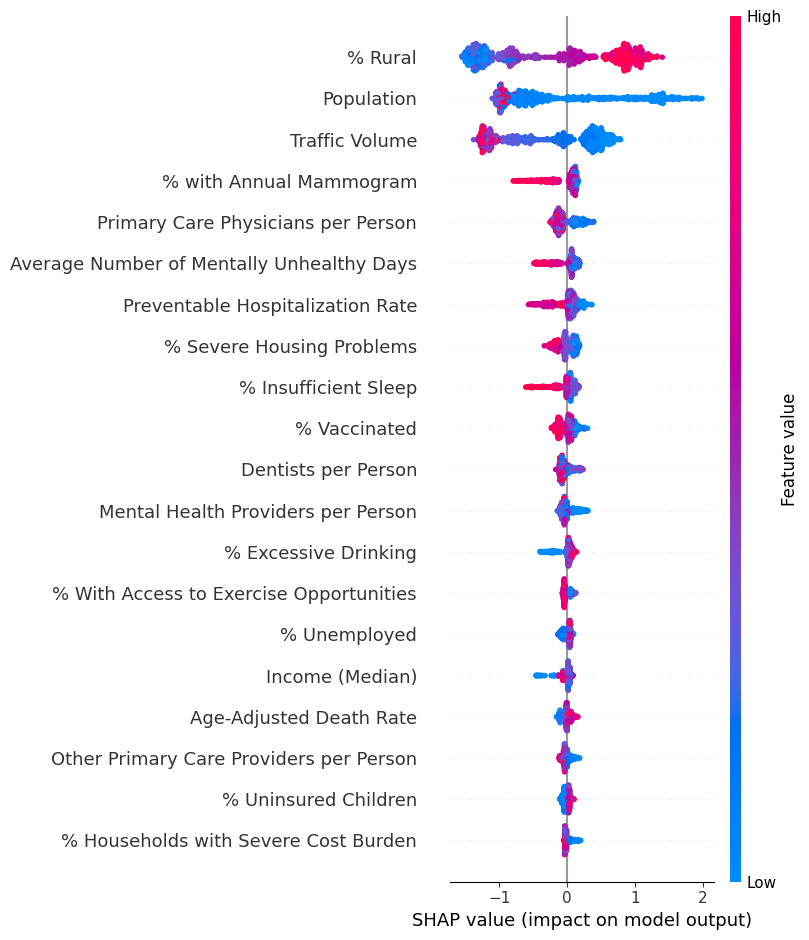

In [ ]:
shap.summary_plot(shap_values, X_full_imp[feature_cols], feature_names=feature_cols)


## 22. Pharmacy Desert Index (Tables 4, 6, 7; Figure 4)

Each feature's direction is the sign of the Pearson correlation between its standardized values and its own SHAP values (the sign of the mean SHAP value is not used, because it can be dominated by the class balance). The PDI is the weighted sum of the percentile ranks (average-rank method, among all 734 counties) of the 11 features with the largest mean |SHAP|, with weights renormalized to sum to 1 over those 11 features. Ranks are reversed for features with a negative direction. Tiers: low ≤ 0.4, medium > 0.4 to 0.6, high > 0.6.

In [ ]:
from scipy.stats import pearsonr

top_n = 11  # number of top-ranked features used in the PDI
top_features = mean_shap_df.head(top_n)['Feature'].tolist()
top_weights = mean_shap_df.head(top_n)['Weight'].values
top_weights = top_weights / top_weights.sum()  # renormalize over the subset actually used in the PDI

# Direction = sign of the Pearson correlation between each feature's standardized value and its
# own SHAP value (not the sign of the mean SHAP value, which can be dominated by the class balance).
feature_corr = {}
for i, feat in enumerate(feature_cols):
    r, _ = pearsonr(X_real_all_scaled[:, i], shap_values[:, i])
    feature_corr[feat] = r
feature_direction = {feat: np.sign(r) for feat, r in feature_corr.items()}

shap_direction_df = pd.DataFrame({
    'Feature': feature_cols,
    'Feature-SHAP correlation': [feature_corr[f] for f in feature_cols],
    'Direction': ['Positive' if feature_direction[f] >= 0 else 'Negative' for f in feature_cols],
})

percentile_ranks = pd.DataFrame(index=X_full_imp.index)
for feat in top_features:
    vals = X_full_imp[feat].values
    ranks = rankdata(vals, method='average') / len(vals)
    if feature_direction[feat] < 0:
        ranks = 1 - ranks
    percentile_ranks[feat] = ranks

pdi_values = percentile_ranks[top_features].values.dot(top_weights)
pdi_df = pd.DataFrame({
    'County, State': df.loc[X_full_imp.index, 'County, State'].values,
    'PDI': np.round(pdi_values, 3)
}).sort_values('PDI', ascending=False).reset_index(drop=True)

print("=== PDI (recomputed, real counties only, CORRECTED direction method) -- Table 6/7 equivalent ===")
print("Top 10:")
print(pdi_df.head(10))
print("\nBottom 10:")
print(pdi_df.tail(10))
print("\nTier counts (0-0.4 / 0.4-0.6 / 0.6-1.0):")
print("  Low:", ((pdi_df['PDI'] >= 0) & (pdi_df['PDI'] <= 0.4)).sum())
print("  Medium:", ((pdi_df['PDI'] > 0.4) & (pdi_df['PDI'] <= 0.6)).sum())
print("  High:", ((pdi_df['PDI'] > 0.6) & (pdi_df['PDI'] <= 1.0)).sum())

# Per-feature breakdown for the #1 county -- this is the data the Principal Findings
# worked-example paragraph needs.
top_county = pdi_df.iloc[0]['County, State']
top_idx = df.index[df['County, State'] == top_county][0]
breakdown_rows = []
for feat, w in zip(top_features, top_weights):
    pct = percentile_ranks.loc[top_idx, feat]
    contrib = w * pct
    breakdown_rows.append({
        'Feature': feat,
        'Weight': round(float(w), 3),
        'Percentile Rank': round(float(pct), 3),
        'Contribution': round(float(contrib), 3),
    })
top_county_breakdown_df = pd.DataFrame(breakdown_rows).sort_values('Contribution', ascending=False)
print(f"\n=== Per-feature breakdown for top county: {top_county} (PDI = {pdi_df.iloc[0]['PDI']}) ===")
print(top_county_breakdown_df.to_string(index=False))
print(f"Sum of contributions: {top_county_breakdown_df['Contribution'].sum():.3f}  (should equal PDI = {pdi_df.iloc[0]['PDI']})")


=== PDI (recomputed, real counties only, CORRECTED direction method) -- Table 6/7 equivalent ===
Top 10:
         County, State    PDI
0        Fisher, TEXAS  0.901
1    Jeff Davis, TEXAS  0.892
2  Throckmorton, TEXAS  0.877
3     Daniels, MONTANA  0.876
4      McCone, MONTANA  0.865
5        Menard, TEXAS  0.864
6   Petroleum, MONTANA  0.864
7        Borden, TEXAS  0.859
8          Kent, TEXAS  0.856
9      Fallon, MONTANA  0.853

Bottom 10:
                  County, State    PDI
724    Montgomery, Pennsylvania  0.112
725           Fayette, KENTUCKY  0.106
726      Delaware, Pennsylvania  0.104
727              Hamilton, OHIO  0.101
728              Franklin, OHIO  0.093
729                 Lucas, OHIO  0.087
730             Marion, INDIANA  0.085
731         Jefferson, KENTUCKY  0.081
732              Cuyahoga, OHIO  0.058
733  Philadelphia, Pennsylvania  0.056

Tier counts (0-0.4 / 0.4-0.6 / 0.6-1.0):
  Low: 242
  Medium: 236
  High: 256

=== Per-feature breakdown for top county: Fi

/tmp/ipykernel_2436/2412424056.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, _ = pearsonr(X_real_all_scaled[:, i], shap_values[:, i])


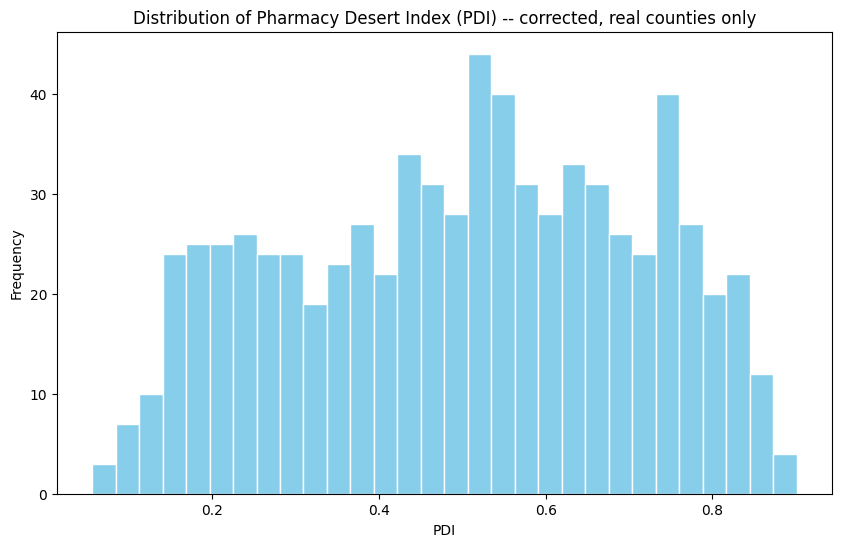

In [ ]:
plt.figure(figsize=(10, 6))
pdi_df['PDI'].plot(kind='hist', bins=30, color='skyblue', edgecolor='white')
plt.title('Distribution of Pharmacy Desert Index (PDI) -- corrected, real counties only')
plt.xlabel('PDI')
plt.ylabel('Frequency')
plt.show()


## 23. Save results

In [ ]:
comparison_df.to_csv('model_comparison_corrected.csv')
cv_robust_df.to_csv('cv_robust_model_comparison.csv')
pd.DataFrame([test_metrics]).assign(model=best_model_name).to_csv('test_set_evaluation.csv', index=False)
pd.DataFrame({'auc': aucs, 'balanced_accuracy': bal_accs}).to_csv('robustness_100fold_cv.csv', index=False)
pdi_df.to_csv('pdi_results_corrected.csv', index=False)
mean_shap_df.to_csv('shap_weights_corrected.csv', index=False)
shap_direction_df.to_csv('shap_direction.csv', index=False)
top_county_breakdown_df.to_csv('top_county_breakdown.csv', index=False)
print("Saved: model_comparison_corrected.csv, cv_robust_model_comparison.csv, test_set_evaluation.csv, "
      "robustness_100fold_cv.csv, pdi_results_corrected.csv, shap_weights_corrected.csv, "
      "shap_direction.csv, top_county_breakdown.csv")
print(f"\nBest model (selected by 50-fold repeated CV): {best_model_name}")
print("\nDONE. Send back all 8 CSVs so the manuscript tables/figures can be cross-checked.")

from google.colab import files
files.download('model_comparison_corrected.csv')
files.download('cv_robust_model_comparison.csv')
files.download('test_set_evaluation.csv')
files.download('robustness_100fold_cv.csv')
files.download('pdi_results_corrected.csv')
files.download('shap_weights_corrected.csv')
files.download('shap_direction.csv')
files.download('top_county_breakdown.csv')


Saved: model_comparison_corrected.csv, cv_robust_model_comparison.csv, test_set_evaluation.csv, robustness_100fold_cv.csv, pdi_results_corrected.csv, shap_weights_corrected.csv, shap_direction.csv, top_county_breakdown.csv

Best model (selected by 50-fold repeated CV): XGBoost

DONE. Send back all 8 CSVs so the manuscript tables/figures can be cross-checked.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (7 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 24. Export per-county predicted probabilities (test set and out-of-fold CV)

Used for the test-set confusion matrix and confidence intervals, the pooled out-of-fold confusion matrix, Brier scores, and the calibration analysis reported in the paper.

In [ ]:
from sklearn.metrics import brier_score_loss

test_prob_export = best_model.predict_proba(X_test_scaled)[:, 1]
test_pred_export = (test_prob_export >= best_threshold).astype(int)

xgboost_test_predictions_df = pd.DataFrame({
    'County': X_test_imp['County'].values,
    'State': X_test_imp['State'].values,
    'y_true': y_test.values,
    'predicted_probability': test_prob_export,
    'predicted_label': test_pred_export,
    'threshold_used': best_threshold,
})
xgboost_test_predictions_df['model'] = best_model_name  # file name kept for continuity; holds the SELECTED model
xgboost_test_predictions_df.to_csv('xgboost_test_predictions.csv', index=False)

print("=== Sanity check: test set ===")
print("Brier score:", brier_score_loss(y_test, test_prob_export))
print("Confusion matrix [[TN,FP],[FN,TP]]:\n", confusion_matrix(y_test, test_pred_export))


=== Sanity check: test set ===
Brier score: 0.07522371953518962
Confusion matrix [[TN,FP],[FN,TP]]:
 [[79 11]
 [ 5 53]]


In [ ]:
oof_rows = []
rskf_export = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
for rep_fold_idx, (tr_idx, te_idx) in enumerate(rskf_export.split(X_trainval_scaled, y_trainval_arr)):
    repeat_num = rep_fold_idx // 5
    fold_num = rep_fold_idx % 5
    m = best_build_fn()
    fit_weighted(m, X_trainval_scaled[tr_idx], y_trainval_arr[tr_idx], sw_trainval[tr_idx])
    prob = m.predict_proba(X_trainval_scaled[te_idx])[:, 1]
    counties = X_trainval_imp['County'].values[te_idx]
    states = X_trainval_imp['State'].values[te_idx]
    for c, s, yt, p in zip(counties, states, y_trainval_arr[te_idx], prob):
        oof_rows.append({'repeat': repeat_num, 'fold': fold_num, 'County': c, 'State': s,
                          'y_true': yt, 'predicted_probability': p})

xgboost_cv_oof_predictions_df = pd.DataFrame(oof_rows)
xgboost_cv_oof_predictions_df['model'] = best_model_name  # file name kept for continuity; holds the SELECTED model
xgboost_cv_oof_predictions_df.to_csv('xgboost_cv_oof_predictions.csv', index=False)

print(f"\n=== Sanity check: pooled out-of-fold CV ({len(xgboost_cv_oof_predictions_df)} rows) ===")
oof_pred_05 = (xgboost_cv_oof_predictions_df['predicted_probability'] >= 0.5).astype(int)
print("Pooled balanced accuracy @ 0.5:", balanced_accuracy_score(xgboost_cv_oof_predictions_df['y_true'], oof_pred_05))
print("Pooled Brier score:", brier_score_loss(xgboost_cv_oof_predictions_df['y_true'], xgboost_cv_oof_predictions_df['predicted_probability']))

from google.colab import files
files.download('xgboost_test_predictions.csv')
files.download('xgboost_cv_oof_predictions.csv')



=== Sanity check: pooled out-of-fold CV (5860 rows) ===
Pooled balanced accuracy @ 0.5: 0.8419535394183282
Pooled Brier score: 0.112561768157194


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 24b. Logistic regression out-of-fold export and paired XGBoost vs logistic regression comparison

Uses the same 50 folds as the XGBoost export, so the two models can be compared fold by fold (Wilcoxon signed-rank test).

In [ ]:
# --- NEW: Logistic Regression fold-level out-of-fold export ---
# Mirrors the XGBoost OOF export above EXACTLY (same RepeatedStratifiedKFold params,
# same RANDOM_STATE, same X_trainval_scaled/y_trainval_arr/sw_trainval inputs), so the
# fold assignments here are identical, row-for-row, to the ones used for XGBoost above.
# This lets the manuscript report a genuine PAIRED comparison (e.g. Wilcoxon signed-rank,
# or a CI on the mean paired balanced-accuracy difference) across the same 50 folds,
# instead of comparing two independently-computed summary statistics.
lr_oof_rows = []
rskf_export_lr = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
for rep_fold_idx, (tr_idx, te_idx) in enumerate(rskf_export_lr.split(X_trainval_scaled, y_trainval_arr)):
    repeat_num = rep_fold_idx // 5
    fold_num = rep_fold_idx % 5
    m = build_fns['Logistic Regression']()
    fit_weighted(m, X_trainval_scaled[tr_idx], y_trainval_arr[tr_idx], sw_trainval[tr_idx])
    prob = m.predict_proba(X_trainval_scaled[te_idx])[:, 1]
    counties = X_trainval_imp['County'].values[te_idx]
    states = X_trainval_imp['State'].values[te_idx]
    for c, s, yt, p in zip(counties, states, y_trainval_arr[te_idx], prob):
        lr_oof_rows.append({'repeat': repeat_num, 'fold': fold_num, 'County': c, 'State': s,
                             'y_true': yt, 'predicted_probability': p})

lr_cv_oof_predictions_df = pd.DataFrame(lr_oof_rows)
lr_cv_oof_predictions_df.to_csv('lr_cv_oof_predictions.csv', index=False)

print(f"\n=== Sanity check: pooled Logistic Regression out-of-fold CV ({len(lr_cv_oof_predictions_df)} rows) ===")
lr_oof_pred_05 = (lr_cv_oof_predictions_df['predicted_probability'] >= 0.5).astype(int)
print("Pooled balanced accuracy @ 0.5:", balanced_accuracy_score(lr_cv_oof_predictions_df['y_true'], lr_oof_pred_05))

# Fold-by-fold paired balanced accuracy, XGBoost vs Logistic Regression (same folds)
xgb_fold_ba = (xgboost_cv_oof_predictions_df.assign(pred=lambda d: (d['predicted_probability']>=0.5).astype(int))
               .groupby(['repeat','fold']).apply(lambda g: balanced_accuracy_score(g['y_true'], g['pred'])))
lr_fold_ba = (lr_cv_oof_predictions_df.assign(pred=lambda d: (d['predicted_probability']>=0.5).astype(int))
              .groupby(['repeat','fold']).apply(lambda g: balanced_accuracy_score(g['y_true'], g['pred'])))
paired = pd.DataFrame({'xgb': xgb_fold_ba, 'lr': lr_fold_ba}).dropna()
paired['diff'] = paired['xgb'] - paired['lr']
paired.to_csv('xgb_vs_lr_paired_folds.csv')
print(f"\nPaired folds: {len(paired)}")
print(f"Mean (XGBoost - LR) balanced accuracy per fold: {paired['diff'].mean():.4f} +/- {paired['diff'].std():.4f}")
from scipy.stats import wilcoxon
try:
    stat, p = wilcoxon(paired['xgb'], paired['lr'])
    print(f"Wilcoxon signed-rank test (XGBoost vs LR, paired by fold): statistic={stat:.3f}, p={p:.4f}")
except Exception as e:
    print("Wilcoxon test could not be run:", e)



=== Sanity check: pooled Logistic Regression out-of-fold CV (5860 rows) ===
Pooled balanced accuracy @ 0.5: 0.8063215657581855

Paired folds: 50
Mean (XGBoost - LR) balanced accuracy per fold: 0.0356 +/- 0.0330
Wilcoxon signed-rank test (XGBoost vs LR, paired by fold): statistic=84.500, p=0.0000


/tmp/ipykernel_2436/493638962.py:31: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .groupby(['repeat','fold']).apply(lambda g: balanced_accuracy_score(g['y_true'], g['pred'])))
/tmp/ipykernel_2436/493638962.py:33: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .groupby(['repeat','fold']).apply(lambda g: balanced_accuracy_score(g['y_true'], g['pred'])))


## 26. Review package: all figures, CSVs, and key numbers in one download

Run last, in the same runtime. Regenerates the figures from the objects in memory, writes `review_summary.txt` with the key numbers (including the leave-one-state-out results), and zips them with the CSVs saved above.

In [ ]:
import os, shutil, zipfile
from datetime import datetime

REVIEW_DIR = 'review_package'
FIG_DIR = os.path.join(REVIEW_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

summary_lines = []
def log(msg=''):
    print(msg)
    summary_lines.append(str(msg))

log('=' * 70)
log('PHARMACY DESERT INDEX -- FULL REVIEW PACKAGE')
log(f'Generated: {datetime.now().isoformat()}')
log('=' * 70)

log('\n--- Dataset ---')
log('Outcome: Nguyen et al. county definition -- desert if >50% of population lives in desert tracts')
log('Class balance (all real counties):\n' + str(df['Desert Y/N'].value_counts()))
log(f'Total real counties: {len(df)}')
log(f'Train: {len(X_train)}  Val: {len(X_val)}  Test: {len(X_test)}')
log('Train class balance:\n' + str(y_train.value_counts()))
log('Val class balance:\n' + str(y_val.value_counts()))
log('Test class balance:\n' + str(y_test.value_counts()))

log('\n--- Table 1 equivalent: 50-fold repeated CV model comparison ---')
log(cv_robust_df.round(4).to_string())

log('\n--- Validation model comparison (all models, incl. LR baseline) ---')
log(comparison_df.round(4).to_string())

log(f'\n--- Best model (by 50-fold CV): {best_model_name} ---')
log(f'Selected threshold: {best_threshold}')
log('Test-set evaluation:')
for k, v in test_metrics.items():
    log(f'  {k}: {v}')
log('Test confusion matrix [[TN,FP],[FN,TP]]:\n' + str(test_cm))

log('\n--- 100-fold repeated CV robustness ---')
log(f'AUC: mean={np.mean(aucs):.4f} sd={np.std(aucs):.4f} '
    f'2.5-97.5pct=[{np.percentile(aucs, 2.5):.4f}, {np.percentile(aucs, 97.5):.4f}]')
log(f'Balanced accuracy: mean={np.mean(bal_accs):.4f} sd={np.std(bal_accs):.4f} '
    f'2.5-97.5pct=[{np.percentile(bal_accs, 2.5):.4f}, {np.percentile(bal_accs, 97.5):.4f}]')

log('\n--- Leave-one-state-out balanced accuracy (recomputed here to actually save it) ---')
loso_rows = []
try:
    for state in sorted(X_full_states.unique()):
        tr_mask = (X_full_states != state).values
        te_mask = (X_full_states == state).values
        if y_full.values[te_mask].sum() == 0 or y_full.values[te_mask].sum() == te_mask.sum():
            log(f'  {state}: skipped (only one class present)')
            continue
        sw = np.where(y_full.values[tr_mask] == 0,
                      (y_full.values[tr_mask] == 1).sum() / max((y_full.values[tr_mask] == 0).sum(), 1), 1.0)
        m = best_build_fn()
        fit_weighted(m, X_full_scaled_for_cv[tr_mask], y_full.values[tr_mask], sw)
        prob = m.predict_proba(X_full_scaled_for_cv[te_mask])[:, 1]
        ba = balanced_accuracy_score(y_full.values[te_mask], (prob >= 0.5).astype(int))
        loso_rows.append({'State': state, 'n': int(te_mask.sum()), 'balanced_accuracy': ba})
        log(f'  {state}: n={te_mask.sum()}, balanced accuracy={ba:.4f}')
    loso_df = pd.DataFrame(loso_rows)
    loso_df.to_csv(os.path.join(REVIEW_DIR, 'loso_balanced_accuracy.csv'), index=False)
except Exception as e:
    log(f'Could not recompute LOSO: {e}')

log('\n--- SHAP weights, top 15 (Table 5 equivalent) ---')
log(mean_shap_df.head(15).round(4).to_string())
log('\n--- SHAP direction, top 11 features used in the PDI (Table 4 equivalent) ---')
log(shap_direction_df.set_index('Feature').loc[top_features].round(4).to_string())
log('Direction counts (all 46 features): ' + str(shap_direction_df['Direction'].value_counts().to_dict()))

log('\n--- PDI distribution (corrected) ---')
log(pdi_df['PDI'].describe().to_string())
log(f"Tier counts -- Low: {((pdi_df['PDI'] >= 0) & (pdi_df['PDI'] <= 0.4)).sum()}, "
    f"Medium: {((pdi_df['PDI'] > 0.4) & (pdi_df['PDI'] <= 0.6)).sum()}, "
    f"High: {((pdi_df['PDI'] > 0.6) & (pdi_df['PDI'] <= 1.0)).sum()}")
log('\nTop 15 counties by PDI:')
log(pdi_df.head(15).to_string(index=False))
log('\nBottom 15 counties by PDI:')
log(pdi_df.tail(15).to_string(index=False))
log(f'\nTop county worked example: {top_county} (PDI={pdi_df.iloc[0]["PDI"]})')
log(top_county_breakdown_df.to_string(index=False))

with open(os.path.join(REVIEW_DIR, 'review_summary.txt'), 'w') as f:
    f.write('\n'.join(summary_lines))

def save_current_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches='tight')
    plt.close()
    print('Saved figure:', name)

def save_feature_importance(name, importances, filename):
    try:
        s = pd.Series(importances, index=feature_cols).sort_values(ascending=False).head(20)
        plt.figure(figsize=(12, 6))
        s.plot(kind='bar', color='skyblue')
        plt.title(f'Feature Importances -- {name}')
        plt.ylabel('Importance')
        save_current_fig(filename)
    except Exception as e:
        print(f'Could not regenerate feature-importance plot for {name}:', e)

try:
    plt.figure(figsize=(10, max(6, len(feature_cols) * 0.25)))
    corr_with_target.sort_values().plot(kind='barh', color='steelblue')
    plt.title('Train-only correlation with Desert Y/N (Figure 2 equivalent)')
    plt.xlabel('Pearson correlation coefficient')
    save_current_fig('fig01_correlation_with_target.png')
except Exception as e:
    print('Could not regenerate fig01:', e)

try:
    plt.figure(figsize=(14, 11))
    sns.heatmap(train_corr_df.corr(), cmap='coolwarm', center=0, annot=False)
    plt.title('Correlation heatmap (training fold only)')
    save_current_fig('fig02_correlation_heatmap.png')
except Exception as e:
    print('Could not regenerate fig02:', e)

save_feature_importance('Logistic Regression', lr.coef_[0], 'fig03_feature_importance_logistic_regression.png')
save_feature_importance('Decision Tree', dt.feature_importances_, 'fig04_feature_importance_decision_tree.png')
save_feature_importance('Random Forest', rf.feature_importances_, 'fig05_feature_importance_random_forest.png')
save_feature_importance('XGBoost', xgb_model.feature_importances_, 'fig06_feature_importance_xgboost.png')
if svm_model.kernel == 'linear':
    save_feature_importance('SVM (linear)', svm_model.coef_[0], 'fig07_feature_importance_svm.png')

try:
    plt.figure(figsize=(10, 6))
    comparison_df['balanced_accuracy'].sort_values().plot(kind='barh', color='steelblue')
    plt.title('Model Comparison: Validation Balanced Accuracy')
    plt.xlabel('Balanced Accuracy')
    save_current_fig('fig08_model_comparison_balanced_accuracy.png')
except Exception as e:
    print('Could not regenerate fig08:', e)

try:
    plt.figure(figsize=(10, 6))
    comparison_df[['sensitivity', 'specificity']].plot(kind='bar')
    plt.title('Model Comparison: Sensitivity vs. Specificity (VAL)')
    plt.ylabel('Score')
    plt.xticks(rotation=45, ha='right')
    save_current_fig('fig09_model_comparison_sensitivity_specificity.png')
except Exception as e:
    print('Could not regenerate fig09:', e)

try:
    shap.summary_plot(shap_values, X_full_imp[feature_cols], feature_names=feature_cols, show=False)
    save_current_fig('fig10_shap_summary_plot.png')
except Exception as e:
    print('Could not regenerate fig10 (SHAP summary):', e)

try:
    plt.figure(figsize=(10, 6))
    pdi_df['PDI'].plot(kind='hist', bins=30, color='skyblue', edgecolor='white')
    plt.title('Distribution of Pharmacy Desert Index (PDI) -- corrected, real counties only')
    plt.xlabel('PDI')
    plt.ylabel('Frequency')
    save_current_fig('fig11_pdi_distribution_corrected.png')
except Exception as e:
    print('Could not regenerate fig11:', e)

csv_names = [
    'model_comparison_corrected.csv', 'cv_robust_model_comparison.csv', 'test_set_evaluation.csv',
    'robustness_100fold_cv.csv', 'pdi_results_corrected.csv', 'shap_weights_corrected.csv',
    'shap_direction.csv', 'top_county_breakdown.csv', 'xgboost_test_predictions.csv',
    'xgboost_cv_oof_predictions.csv',
    'lr_cv_oof_predictions.csv', 'xgb_vs_lr_paired_folds.csv',
    'all_models_fold_metrics.csv', 'all_models_test_evaluation.csv', 'all_models_test_predictions.csv',
]
for name in csv_names:
    if os.path.exists(name):
        shutil.copy(name, os.path.join(REVIEW_DIR, name))
    else:
        print(f'WARNING: {name} not found -- run the earlier save cells first.')

zip_path = 'pharmacy_desert_review_package_outcome50.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for root, _, fnames in os.walk(REVIEW_DIR):
        for fname in fnames:
            full = os.path.join(root, fname)
            zf.write(full, os.path.relpath(full, REVIEW_DIR))

print('\nReview package built:', zip_path)
from google.colab import files
files.download(zip_path)


PHARMACY DESERT INDEX -- FULL REVIEW PACKAGE
Generated: 2026-11-11T02:08:28.806919

--- Dataset ---
Outcome: Nguyen et al. county definition -- desert if >50% of population lives in desert tracts
Class balance (all real counties):
Desert Y/N
0    445
1    289
Name: count, dtype: int64
Total real counties: 734
Train: 513  Val: 73  Test: 148
Train class balance:
Desert Y/N
0    311
1    202
Name: count, dtype: int64
Val class balance:
Desert Y/N
0    44
1    29
Name: count, dtype: int64
Test class balance:
Desert Y/N
0    90
1    58
Name: count, dtype: int64

--- Table 1 equivalent: 50-fold repeated CV model comparison ---
               auc_mean  auc_sd  balanced_accuracy_mean  balanced_accuracy_sd
XGBoost          0.9226  0.0214                  0.8420                0.0298
Random Forest    0.9228  0.0213                  0.8325                0.0330
SVM              0.9062  0.0205                  0.8164                0.0317
Decision Tree    0.8606  0.0287                  0.7926    

/tmp/ipykernel_2436/836873017.py:150: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_full_imp[feature_cols], feature_names=feature_cols, show=False)


Saved figure: fig10_shap_summary_plot.png
Saved figure: fig11_pdi_distribution_corrected.png

Review package built: pharmacy_desert_review_package_outcome50.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>